# Worked example

This tutorial forward models the Fe XII 195.119 line from a MURaM simulation of an active region through EUVST-SW, and maps what the instrument would measure. It goes through every step: reading the simulation, writing it as an atmosphere file, synthesising the spectra, simulating the instrument and making maps of the results. The simulation covers 300 by 300 arcsec, so it fills EUVST's slit.

**The simulation is a test release, not for scientific use.** In Fe XII its quiet Sun is two to three times brighter than the quiet Sun EIS observes, and its active region core is fainter than EIS active regions. Lines that form below about 0.6 MK are not reliable in it. Use it to learn ECLIPSE, not to draw conclusions about the Sun.

## Before you start

| Resource | Needed |
| --- | --- |
| Download | 11 GB, three of the simulation's files |
| Disk | about 30 GB |
| Memory | about 330 GB for the synthesis, and 20 GB for the rest |
| Wall clock | about half an hour on 128 cores |

To use less memory, add `--downsample 2` to the synthesis. It averages the simulation's cells in pairs along each horizontal axis, and needs about a quarter of the memory.

Contribution functions come from CHIANTI through [fiasco](https://fiasco.readthedocs.io/), which needs a local copy of the CHIANTI database. The first synthesis offers to download and build it, about 600 MB; see [Getting started](../quickstart/).

In [1]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

from eclipse import (
    Atmosphere,
    create_sunpy_maps_from_combo,
    edges_from_centres,
    load_instrument_response_results,
    write_atmosphere,
)

## 1. Download the simulation

The simulation is MURaM run 006, snapshot 1160000, on the UCL Research Data Repository (DOI to come). Each of its files holds one quantity. The synthesis needs three of them:

- `eosT.1160000`: the temperature, in K;
- `result_prim_0.1160000`: the mass density, in g / cm3;
- `result_prim_1.1160000`: the vertical velocity, in cm / s, positive upward.

Download these three into a folder called `muram_ar`.

In [2]:
SNAPSHOT = 1160000
FOLDER = Path("muram_ar")
NAMES = ("eosT", "result_prim_0", "result_prim_1")

for name in NAMES:
    path = FOLDER / f"{name}.{SNAPSHOT}"
    assert path.exists(), f"Download {path.name} from the dataset into {FOLDER}"
    print(path, f"{path.stat().st_size / 1e9:.1f} GB")

muram_ar/eosT.1160000 3.7 GB
muram_ar/result_prim_0.1160000 3.7 GB
muram_ar/result_prim_1.1160000 3.7 GB


## 2. Write the atmosphere file

Each file is the quantity in every cell, as 32-bit floats, ordered by y, then x, then height, with height changing fastest. The box is 1088 by 1088 cells of 200 km across, and 781 cells of 64 km in height, from 8 Mm below the photosphere to 42 Mm above it.

Only the heights above 1 Mm are kept. The cooler layers below do not emit Fe XII, and leaving them out saves memory.

In [3]:
NX = NY = 1088
NZ = 781
z = (np.arange(NZ) + 0.5) * 0.064 - 8.016   # height of each cell's centre above the photosphere, Mm
keep = z >= 1.0
x = (np.arange(NX) + 0.5 - NX / 2) * 0.2    # Mm


def variable(name):
    """One of the simulation's files, as (height, y, x), above 1 Mm."""
    cube = np.fromfile(FOLDER / f"{name}.{SNAPSHOT}", dtype="<f4").reshape(NY, NX, NZ)
    return np.ascontiguousarray(cube[:, :, keep].transpose(2, 0, 1))


atmosphere = Atmosphere(
    temperature=variable("eosT") * u.K,
    mass_density=variable("result_prim_0") * u.g / u.cm**3,
    velocity_z=variable("result_prim_1") * u.cm / u.s,
    x_edges=edges_from_centres(x * u.Mm), y_edges=edges_from_centres(x * u.Mm),
    z_edges=edges_from_centres(z[keep] * u.Mm),
    time=566510.0 * u.s,
    source=f"MURaM 300 arcsec active region, run 006, snapshot {SNAPSHOT}",
)
write_atmosphere(atmosphere, f"muram_ar_{SNAPSHOT}.h5")
print(atmosphere.describe())

  Shape (nz, ny, nx): (640, 1088, 1088)
  x: -108.800 Mm to 108.800 Mm, cells of 0.2000 Mm
  y: -108.800 Mm to 108.800 Mm, cells of 0.2000 Mm
  z: 1.008 Mm to 41.968 Mm, cells of 0.0640 Mm
  Density: mass_density
  Velocities: z
  Time: 566510.000 s
  Source: MURaM 300 arcsec active region, run 006, snapshot 1160000


## 3. Synthesise the line

The file gives the mass density, so ECLIPSE works out the electron density by dividing it by the mass per free electron. The simulation's own equation of state gives 1.19 atomic mass units per electron in the corona, so `--mass-per-electron 1.19` matches the electron density the simulation had. Fe XII 195.179 lies in the same window as 195.119, so both are synthesised.

`--goft-temperature-chunk` and `--precision float32` keep the memory down; see [From an MHD simulation](../synthesis/).

In [4]:
!synthesise-spectra --atmosphere muram_ar_1160000.h5 \
  --lines Fe12_195.1190 Fe12_195.1790 \
  --mass-per-electron 1.19 \
  --goft-temperature-chunk 20 --precision float32 \
  --output-dir ./run/input --output-name muram_ar_fe12.h5

STATIC MODE - Synthesis from an atmosphere file
  Atmosphere: muram_ar_1160000.h5
  Integration axis: z
  Velocity grid: +/-300.0 km / s at 5.0 km / s resolution
  Precision: <class 'numpy.float32'>
  Lines: ['Fe12_195.1190', 'Fe12_195.1790']
  Abundance: sun_coronal_2021_chianti

Reading the atmosphere (25.95/540.76 GB)


  Shape (nz, ny, nx): (640, 1088, 1088)
  x: -108.800 Mm to 108.800 Mm, cells of 0.2000 Mm
  y: -108.800 Mm to 108.800 Mm, cells of 0.2000 Mm
  z: 1.008 Mm to 41.968 Mm, cells of 0.0640 Mm
  Density: mass_density
  Velocities: z
  Time: 566510.000 s
  Source: MURaM 300 arcsec active region, run 006, snapshot 1160000


Electron density from the mass density with 1.1900 u per electron (given on the command line)


Computing contribution functions via fiasco at 10^6.7 to 10^13.0 cm^-3 (53.27/540.76 GB)
  101 temperatures in chunks of 20


  Fe12_195.1190: requested 195.1190 Angstrom, matched 195.1190 Angstrom, observed (delta=0.0000 Angstrom)
  Fe12_195.1790: requested 195.1790 Angstrom, matched 195.1790 Angstrom, observed (delta=0.0000 Angstrom)
Calculating the DEM, the emission measure in (T,v) and the spectra (53.20/540.76 GB)


  Building 4-D emission-measure cube along z-axis...


Creating output cubes (110.65/540.76 GB)


Built 2 line cubes


Saved results to run/input/muram_ar_fe12.h5 (5785.25 MB)
Synthesis complete!


## 4. Simulate the instrument

The configuration observes the synthesis with EUVST-SW, with the 0.4 arcsec slit and 60 s exposures:

- `psf` and `slit_mask` blur the scene with the instrument's PSF and block the light behind the slit's fiducials.
- `offchip_bin_slit: 2` adds pairs of pixels along the slit after read-out, which gives more photons per pixel.
- `n_iter: 10` repeats the observation ten times, each with new noise, to measure how precisely each pixel's velocity is found.
- `fitting` fits Fe XII 195.119 and 195.179 together, as eispac's template for this blend does; see [A faint blend](../fitting/#a-faint-blend).

In [5]:
%%writefile run/input/muram_ar_fe12.yaml
instrument: SWC
synthesis_file: ./run/input/muram_ar_fe12.h5
reference_line: Fe12_195.1190

n_iter: 10
ncpu: -1
fit_signals: dn
offchip_bin_slit: 2

simulation:
  slit_width: 0.4 arcsec
  expos: 60 s
  psf: True
  slit_mask: True

fitting:
  start: rest
  constrain_positive_intensity: true
  components:
    - wavelength: 195.119 angstrom
      name: Fe XII 195.119
      velocity_limits: [-61.5 km/s, 61.5 km/s]
      width_limits: [0.0191 angstrom, 0.0510 angstrom]
    - wavelength: 195.179 angstrom
      name: Fe XII 195.179
      tie_center: 0
      tie_width: 0

Writing run/input/muram_ar_fe12.yaml


In [6]:
!eclipse --config run/input/muram_ar_fe12.yaml

  ______ _____ _      _____ _____   _____ ______
 |  ____/ ____| |    |_   _|  __ \ / ____|  ____|
 | |__ | |    | |      | | | |__) | (___ | |__
 |  __|| |    | |      | | |  ___/ \___ \|  __|
 | |___| |____| |____ _| |_| |     ____) | |____
 |______\_____|______|_____|_|    |_____/|______|

ECLIPSE: Emission Calculation and Line Prediction for SOLAR-C EUVST

Contact: James McKevitt (jm2@mssl.ucl.ac.uk). See LICENSE for usage terms.

Running instrument response simulation with config: run/input/muram_ar_fe12.yaml
------------------------------------------------------------
Multi-component fitting enabled: 2 components (primary=0, 7 params, backend=scipy (auto))
Fitting only 'dn' signal (skipping 'photon')
DN fits weighted by each pixel's uncertainty, photon fits by their Poisson likelihood
Off-chip slit binning values: [2] (ground-based, all noise per pixel before summation)

Running 1 parameter combination(s).

Loading the synthesis from ./run/input/muram_ar_fe12.h5...
Using 'Fe12_19

  Lines in its window: Fe12_195.1190, Fe12_195.1790
  Source: MURaM 300 arcsec active region, run 006, snapshot 1160000


Rebinning atmosphere (slit_width=0.4 arcsec, plate_scale=0.159 arcsec / pix, wvl_res=1.6900000000000004e-10 cm / pix)...
  Spectral rebinning to instrument resolution (ny,nx,*nl*)...


  Spatially rebinning to plate scale (*ny*,nx,nl) and slit width (ny,*nx*,nl)...


Laying the scene onto the detector through the telescope...
  Spectral rebinning to instrument resolution (ny,nx,*nl*)...


...

--- Combination 1/1 ---
  offchip_bin_slit: 2
  Calculated dark current: 2.15e+00 electron / (pix s)
  Microroughness sigma: 0.3 nm


Fitting ground truth cube (offchip_bin_slit=2)...


  DN fits: none of 7072500 failed


Saving results to run/result/muram_ar_fe12.h5


Saved results to run/result/muram_ar_fe12.h5 (1385.7 MB)
Software version: 0.13.1  |  Git commit: 49b1b327cac53ca8286340f46fd0336a7c1514a3
Instrument response simulation complete! Total combinations: 1


## 5. Load the results

The results file holds every combination of the settings in the configuration. This run has only one. `summary_table(results)` prints every setting the run used.

In [7]:
results = load_instrument_response_results("run/result/muram_ar_fe12.h5")
combination = next(iter(results["results"]["all_combinations"].values()))

# A simulation has no date of its own, so the maps are given one.
maps = create_sunpy_maps_from_combo(combination, date_obs="2026-01-01T00:00:00")

## 6. The maps

`total_dn` is the signal in the Fe XII window, summed over wavelength, from the first of the ten observations. It is an ordinary SunPy map. The two dark rows are the slit's fiducials.

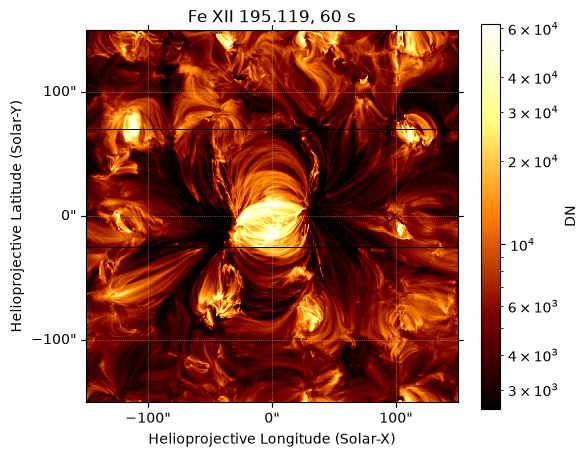

In [8]:
intensity = maps["total_dn"]
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection=intensity)
image = intensity.plot(axes=ax, title="Fe XII 195.119, 60 s",
                       norm=LogNorm(*np.nanpercentile(intensity.data, [1, 99.9])))
fig.colorbar(image, ax=ax, label="DN")
plt.show()

`velocity_true` is the Doppler velocity fitted to the spectra with no noise and no PSF, and `velocity_from_fit` is the velocity measured in the first observation. Away from the darkest parts of the field, the measurement follows the flows of the simulation.

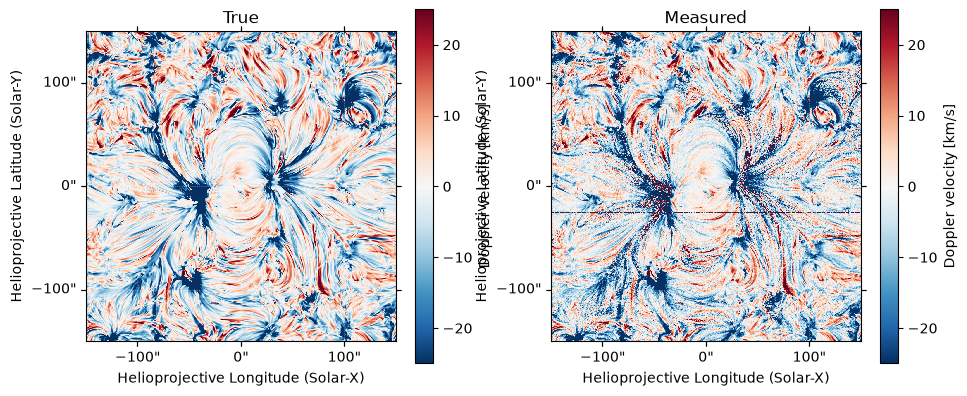

In [9]:
fig = plt.figure(figsize=(11, 4.6))
for i, (key, title) in enumerate((("velocity_true", "True"), ("velocity_from_fit", "Measured"))):
    velocity = maps[key]
    ax = fig.add_subplot(1, 2, i + 1, projection=velocity)
    image = velocity.plot(axes=ax, title=title, cmap="RdBu_r", vmin=-25, vmax=25)
    fig.colorbar(image, ax=ax, label="Doppler velocity [km/s]")
plt.show()

`velocity_std` is the standard deviation of the measured velocity over the ten observations: how precisely EUVST-SW measures each pixel's velocity in a 60 s exposure.

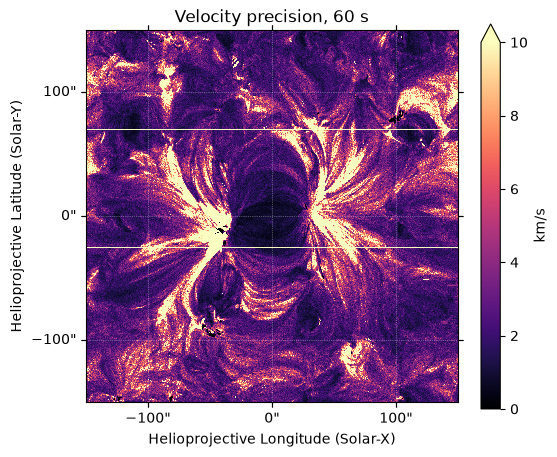

In [10]:
precision = maps["velocity_std"]
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection=precision)
image = precision.plot(axes=ax, title="Velocity precision, 60 s", vmin=0, vmax=10)
fig.colorbar(image, ax=ax, label="km/s", extend="max")
plt.show()

[Analysing the results](../analysis/) describes the other maps and how to compare combinations. [A full-CCD frame](../full-ccd-frame/) makes the frame the camera reads out at one slit position, with every line in the band.